# Experiment on Decision Tree and Random Forest for Credit Card Frad Data from 2023.

In Machine Learning One way to prevent overfitting that we learned in class is dimension reduction.
I am well aware that RandomForest usually performs better than Decision Tree, but I want to see weather dimension reduction improve validation score. 


I asked AI what is a smart way to peform dimension reduction ... And the rest will be in my analysis.

1. **Decision Tree** (`DecisionTreeClassifier`)
2. **Random Forest** (`RandomForestClassifier`)

Additionally, In class we also learned about regularization, so I decided to sweep over min_leaf_samples parameter to find a solid tree that does not overfit. 



In [1]:
%pip install scikit-learn
%pip install graphviz
%pip install seaborn


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: /Users/harrisonyeboah/Desktop/CS Coursework/CS240/kmeans/kmeans/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: /Users/harrisonyeboah/Desktop/CS Coursework/CS240/kmeans/kmeans/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: /Users/harrisonyeboah/Desktop/CS Coursework/CS240/kmeans/kmeans/bin/python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Imports 
These are where all my library imports are. 



In [2]:
import pandas as pd
import numpy as np
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

def print_confusion(label, y_true, y_pred):
    # I import confusion matrix from sk learn 
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    print(f"  My Confusion matrix ({label}) [rows=actual, cols=predicted]")
    print(f"                 Pred 0   Pred 1")
    print(f"    Actual 0  {cm[0,0]:6d}   {cm[0,1]:6d}   (TN, FP)")
    print(f"    Actual 1     {cm[1,0]:6d}   {cm[1,1]:6d}   (FN, TP)")
    return cm


## 1. Load the data

The data comes from `creditcard_2023.csv`. The `id` column is dropped because it leaks the label: low ids are all Class 0 and high ids are all Class 1, so a model could score well by learning the id instead of the features.

In [3]:
# This is my dataset from Kaggle 
df = pd.read_csv("creditcard_2023.csv")

# I drop the id column since that is a data leak it helps us basically predict since the second half of dataset is all fraud. 
df = df.drop(columns="id")

Quick look at the first rows to check the columns and values.

In [4]:
# This gives us a good I dea of what the head looks like. 
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-0.260648,-0.469648,2.496266,-0.083724,0.129681,0.732898,0.519014,-0.130006,0.727159,0.637735,...,-0.110552,0.217606,-0.134794,0.165959,0.126280,-0.434824,-0.081230,-0.151045,17982.10,0
1,0.985100,-0.356045,0.558056,-0.429654,0.277140,0.428605,0.406466,-0.133118,0.347452,0.529808,...,-0.194936,-0.605761,0.079469,-0.577395,0.190090,0.296503,-0.248052,-0.064512,6531.37,0
2,-0.260272,-0.949385,1.728538,-0.457986,0.074062,1.419481,0.743511,-0.095576,-0.261297,0.690708,...,-0.005020,0.702906,0.945045,-1.154666,-0.605564,-0.312895,-0.300258,-0.244718,2513.54,0
3,-0.152152,-0.508959,1.746840,-1.090178,0.249486,1.143312,0.518269,-0.065130,-0.205698,0.575231,...,-0.146927,-0.038212,-0.214048,-1.893131,1.003963,-0.515950,-0.165316,0.048424,5384.44,0
4,-0.206820,-0.165280,1.527053,-0.448293,0.106125,0.530549,0.658849,-0.212660,1.049921,0.968046,...,-0.106984,0.729727,-0.161666,0.312561,-0.414116,1.071126,0.023712,0.419117,14278.97,0


## 2. Helper functions

**`normalize_df`** this will scale all the columns with SciKitMinMaxScaler to prevent certain features from overlapping.

In [5]:
def normalize_df(df):
    # Make a copy of the df
    df_normalized = df.copy()

    # Get all the numeric columns
    numeric_cols = df_normalized.select_dtypes(
        include="number"
    ).columns

    # Normalize df with scikit learn normalizer
    scaler = MinMaxScaler()
    df_normalized[numeric_cols] = scaler.fit_transform(
        df_normalized[numeric_cols]
    )

    # return the df_normalized
    return df_normalized

**`split_sets`** builds all six datasets used in the experiments:

This will build all datasets for testing, training, and validation. This will also do the same for the PCA dimenison reduced sets for my hypothesis. 

It returns the three original sets followed by the three PCA sets.

In [6]:
def split_sets(df, n_components=8):
    # This will get us the number of rows, so we can split by thirds. 
    total_numb_rows = len(df)

    # This is for when we will divide each row by three for training_set, validation_set, and testing set
    one_third_length_rows = int(total_numb_rows / 3)

    print(one_third_length_rows)
    # I will shuffle the df just in case the first half is all Class = 1 and the second half is all Class = 0
    df_shuffled = df.sample(frac=1, ignore_index=True, random_state=42)

    # I will get the first third for the training set, the second third for the validation_set, and the latter third for the 
    training_set = df_shuffled[:one_third_length_rows]
    validation_set = df_shuffled[one_third_length_rows:one_third_length_rows * 2]
    testing_set = df_shuffled[one_third_length_rows * 2:]

    # Dimenison Reduced Sets with PCA.
    # There could potentially be overfitting. I Due to the fact that there is 28 total features. 
    # I asked AI what are some ways to perfrom dimension reduction to give me an idea. 
    # AI recommended PCA and then I Implemented it to experiment and see if this could potentially solve overfitting. 

    feature_cols = [c for c in training_set.columns if c != "Class"]
    pc_cols = [f"PC{i + 1}" for i in range(n_components)]

    # We only want 8 features. 
    pca = PCA(n_components=n_components)

    # We then perform pca on the datasets with 28 rows and perform dimension reduction to compare accuracy between the two to see if there are any improvements.  
    # (PCA is fit on the training set only, then the same transform is applied to validation and testing)
    training_pca = pd.DataFrame(pca.fit_transform(training_set[feature_cols]), columns=pc_cols)
    validation_pca = pd.DataFrame(pca.transform(validation_set[feature_cols]), columns=pc_cols)
    testing_pca = pd.DataFrame(pca.transform(testing_set[feature_cols]), columns=pc_cols)

    training_pca["Class"] = training_set["Class"].to_numpy()
    validation_pca["Class"] = validation_set["Class"].to_numpy()
    testing_pca["Class"] = testing_set["Class"].to_numpy()

    # Return the split sets no I put no scaling, when I scaled my results were worse
    return (training_set, validation_set, testing_set,
            training_pca, validation_pca, testing_pca)


**`get_correlation_heatmap`** This shows how correlated each of the features are to each other. Not really useful. I though I was going to need it but this is now for the sake of my project looking cool. 

In [7]:
def get_correlation_heatmap(training_set, threshold=0.3):
    # Get correlations between numerical columns
    corr = training_set.select_dtypes(include="number").corr()

    plt.figure(figsize=(14, 10))
    sns.heatmap(
        corr,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0
    )
    plt.title("Feature Correlation Heatmap")
    plt.tight_layout()
    plt.show()

    # Find columns with low correlation to all other columns
    low_correlation_columns = [
        col for col in corr.columns
        if (corr[col].drop(labels=[col]).abs() < threshold).all()
    ]

    return low_correlation_columns

## 3. Tuning

**`get_best_depth_tree`** tunes a single decision tree:

1. Separate the observations and the predicitons. 
2. Run a loop through each min_sample_leaf then chose the one with the highest validation score. 
3. Print F1 score each of the validations and run with the min_leafs_sample with the highest one.
4. Refit on the training set with the best min_sample_leaf then after that run a prediciton on it with the testing set. 
5. Return the result. 

The validation is key to prevent memorizaiton 

In [8]:
def get_best_depth_tree(training_set, validation_set, testing_set):
    # This will be our current_depth_that will work its way up to 15. 

    leaf_sizes = [600, 400, 250, 150, 100, 75, 50, 35, 20, 10, 5, 2, 1]
    iteration = 0

    # This is where we store each leaf size and its F1 scores so we can graph them later
    results = {'params': [], 'train_f1': [], 'val_f1': []}
    min_sample_leaf_of_process = 100

    #TRAINING SET X, Y

    # This will be each person excluding Class
    training_set_x = training_set.drop(columns="Class")

    # This will be each person excluding Class
    training_set_y = training_set['Class']

    
    # This is the numpy array of the training set
    training_set_x_np = training_set_x.to_numpy() 
    training_set_y_np = training_set_y.to_numpy() 


    # VALIDATION SET X, Y

    # This will be each person excluding Class
    validation_set_x = validation_set.drop(columns="Class")

    # This will be each person excluding Class
    validation_set_y = validation_set['Class']

    
    # This is the numpy array of the training set
    validation_set_x_np = validation_set_x.to_numpy() 
    validation_set_y_np = validation_set_y.to_numpy() 


    # TESTING SET X, Y

    # This will be each person excluding Class
    testing_set_x = testing_set.drop(columns="Class")

    # This will be each person excluding Class
    testing_set_y = testing_set['Class']

    
    # This is the numpy array of the training set
    testing_set_x_np = testing_set_x.to_numpy() 
    testing_set_y_np = testing_set_y.to_numpy() 

    
    # This is where we will store the best tree. With an updating variable. 
    # Right now the first leaf in leaf_sizes the one with the best score but is more than likely going to update
    best_min_sample_leaf = leaf_sizes[0]
    current_best_f1 = 0
    
    # This will be our four loop until max depth of 15 I chose 15 as the max depth 
    while (iteration < len(leaf_sizes)):
        # We are fitting a tree at each max depth with training set
        current_decision_tree = tree.DecisionTreeClassifier(min_samples_leaf=leaf_sizes[iteration], class_weight= "balanced", random_state=42)
        current_decision_tree = current_decision_tree.fit(training_set_x_np, training_set_y_np)


        #Training_set prediction. This prediciton will get the prediciton of the testing set and calculate the f1 score this should usually be higher than validation.
        training_set_predicition = current_decision_tree.predict(training_set_x_np.tolist())
        training_f1 = f1_score(training_set_y_np, training_set_predicition)
        
        # Using that fitted tree on validation get the predcition on validation set
        validation_set_predicition = current_decision_tree.predict(validation_set_x_np.tolist())
        validation_f1 = f1_score(validation_set_y_np, validation_set_predicition)

        # If if current validation score is higher then the current highest update.
        # We also update teh best min sample leaf
        if validation_f1 > current_best_f1:
            current_best_f1 = validation_f1
            best_min_sample_leaf = leaf_sizes[iteration]
        
        print(f"Iteration: {iteration + 1}; with Mininum Leaf Size: {leaf_sizes[iteration]}; F1 Score (Training Set): {training_f1}, F1 Score (Validation Set) {validation_f1}")
        
        

        print("")

        # Save this iteration so we can graph it later
        results['params'].append(leaf_sizes[iteration])
        results['train_f1'].append(training_f1)
        results['val_f1'].append(validation_f1)

        iteration += 1


    # Once we finish iterating, refit the best model on the TRAINING set only (never the testing set)
    best_tree = tree.DecisionTreeClassifier(min_samples_leaf=best_min_sample_leaf, class_weight= "balanced", random_state=42)  
    best_tree = best_tree.fit(training_set_x_np, training_set_y_np)

    # Now we use the best model (not the last one from the loop) to predict the testing set and get its f1 score
    testing_set_predicition = best_tree.predict(testing_set_x_np.tolist())
    testing_f1 = f1_score(testing_set_y_np, testing_set_predicition)

    print("")
    print("Final Result")
    print(f"Minimum Leaf Size: {best_min_sample_leaf}; F1 Score (Testing Set): {testing_f1}")

    # Confusion matrix for the testing set
    test_cm = print_confusion("Testing", testing_set_y_np, testing_set_predicition)

    results['best_param'] = best_min_sample_leaf
    results['test_f1'] = testing_f1
    results['test_cm'] = test_cm
    return results
        

**`get_best_depth_random_forest_tree`** Does the exact same at the top just copy and pasted and changed the tree. 


In [9]:
def get_best_depth_random_forest_tree(training_set, validation_set, testing_set):
    # This will be our current_depth_that will work its way up to 15. 

    leaf_sizes = [600, 400, 250, 150, 100, 75, 50, 35, 20, 10, 5, 2, 1]
    iteration = 0

    # This is where we store each leaf size and its F1 scores so we can graph them later
    results = {'params': [], 'train_f1': [], 'val_f1': []}
    min_sample_leaf_of_process = 100

    #TRAINING SET X, Y

    # This will be each person excluding Class
    training_set_x = training_set.drop(columns="Class")

    # This will be each person excluding Class
    training_set_y = training_set['Class']

    
    # This is the numpy array of the training set
    training_set_x_np = training_set_x.to_numpy() 
    training_set_y_np = training_set_y.to_numpy() 


    # VALIDATION SET X, Y

    # This will be each person excluding Class
    validation_set_x = validation_set.drop(columns="Class")

    # This will be each person excluding Class
    validation_set_y = validation_set['Class']

    
    # This is the numpy array of the training set
    validation_set_x_np = validation_set_x.to_numpy() 
    validation_set_y_np = validation_set_y.to_numpy() 


    # TESTING SET X, Y

    # This will be each person excluding Class
    testing_set_x = testing_set.drop(columns="Class")

    # This will be each person excluding Class
    testing_set_y = testing_set['Class']

    
    # This is the numpy array of the training set
    testing_set_x_np = testing_set_x.to_numpy() 
    testing_set_y_np = testing_set_y.to_numpy() 

    
    # This is where we will store the best tree. With an updating variable. 
    # Right now the first leaf in leaf_sizes the one with the best score but is more than likely going to update
    best_min_sample_leaf = leaf_sizes[0]
    current_best_f1 = 0
    
    # This will be our four loop until max depth of 15 I chose 15 as the max depth 
    while (iteration < len(leaf_sizes)):
        # We are fitting a tree at each max depth with training set
        current_decision_tree = RandomForestClassifier(min_samples_leaf=leaf_sizes[iteration], class_weight= "balanced", random_state=42)
        current_decision_tree = current_decision_tree.fit(training_set_x_np, training_set_y_np)


        #Training_set prediction. This prediciton will get the prediciton of the testing set and calculate the f1 score this should usually be higher than validation.
        training_set_predicition = current_decision_tree.predict(training_set_x_np.tolist())
        training_f1 = f1_score(training_set_y_np, training_set_predicition)
        
        # Using that fitted tree on validation get the predcition on validation set
        validation_set_predicition = current_decision_tree.predict(validation_set_x_np.tolist())
        validation_f1 = f1_score(validation_set_y_np, validation_set_predicition)

        # If if current validation score is higher then the current highest update.
        # We also update teh best min sample leaf
        if validation_f1 > current_best_f1:
            current_best_f1 = validation_f1
            best_min_sample_leaf = leaf_sizes[iteration]
        
        print(f"Iteration: {iteration + 1}; with Mininum Leaf Size: {leaf_sizes[iteration]}; F1 Score (Training Set): {training_f1}, F1 Score (Validation Set) {validation_f1}")
        
        
        # Confusion matrices for this leaf size (rows = actual, cols = predicted)
        print_confusion("Training", training_set_y_np, training_set_predicition)
        print_confusion("Validation", validation_set_y_np, validation_set_predicition)
        print("")

        # Save this iteration so we can graph it later
        results['params'].append(leaf_sizes[iteration])
        results['train_f1'].append(training_f1)
        results['val_f1'].append(validation_f1)

        iteration += 1


    # Once we finish iterating, refit the best model on the TRAINING set only (never the testing set)
    best_tree = RandomForestClassifier(min_samples_leaf=best_min_sample_leaf, class_weight= "balanced", random_state=42)  
    best_tree = best_tree.fit(training_set_x_np, training_set_y_np)

    # Now we use the best model (not the last one from the loop) to predict the testing set and get its f1 score
    testing_set_predicition = best_tree.predict(testing_set_x_np.tolist())
    testing_f1 = f1_score(testing_set_y_np, testing_set_predicition)

    print("")
    print("Final Result")
    print(f"Minimum Leaf Size: {best_min_sample_leaf}; F1 Score (Testing Set): {testing_f1}")

    # Confusion matrix for the testing set
    test_cm = print_confusion("Testing", testing_set_y_np, testing_set_predicition)

    results['best_param'] = best_min_sample_leaf
    results['test_f1'] = testing_f1
    results['test_cm'] = test_cm
    return results
        

## 4. Example tree

An example of what the tree looks like. 

[Text(0.5, 0.8333333333333334, 'x[13] <= 0.007\ngini = 0.5\nsamples = 568630\nvalue = [284315, 284315]'),
 Text(0.25, 0.5, 'x[3] <= -0.746\ngini = 0.054\nsamples = 259858\nvalue = [7162, 252696]'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'gini = 0.276\nsamples = 3073\nvalue = [2566, 507]'),
 Text(0.375, 0.16666666666666666, 'gini = 0.035\nsamples = 256785\nvalue = [4596, 252189]'),
 Text(0.75, 0.5, 'x[3] <= -0.022\ngini = 0.184\nsamples = 308772\nvalue = [277153, 31619]'),
 Text(0.625, 0.6666666666666667, '  False'),
 Text(0.625, 0.16666666666666666, 'gini = 0.103\nsamples = 267337\nvalue = [252847, 14490]'),
 Text(0.875, 0.16666666666666666, 'gini = 0.485\nsamples = 41435\nvalue = [24306, 17129]')]

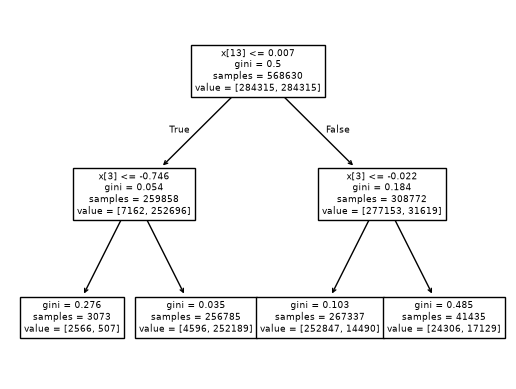

In [10]:
# Example tree. 
x = df.drop(columns="Class")
y = df['Class']
x_result = x.to_numpy()
y_result = y.to_numpy()
clf = tree.DecisionTreeClassifier(max_depth = 2)
clf = clf.fit(x_result, y_result)
tree.plot_tree(clf)

## 5. Build the datasets

Creates the non-PCA sets (`training_set`, `validation_set`, `testing_set`) and the PCA sets (`training_pca`, `validation_pca`, `testing_pca`) with `split_sets`.

In [11]:
# My hypothesis sets to compare. 
(training_set, validation_set, testing_set, training_pca, validation_pca, testing_pca) = split_sets(df)


189543


## 6. Run the experiments

Each cell tunes one model on one version of the data and prints the F1 scores and confusion matrices for every leaf size, then the final test result.

**Decision Tree, non-PCA features**

In [12]:
# Regular decision tree without dimension reduction. 
dt_no_dim_reduct = get_best_depth_tree(training_set, validation_set, testing_set)

Iteration: 1; with Mininum Leaf Size: 600; F1 Score (Training Set): 0.9618543665593489, F1 Score (Validation Set) 0.9609386603297193

Iteration: 2; with Mininum Leaf Size: 400; F1 Score (Training Set): 0.9665467033113075, F1 Score (Validation Set) 0.9653557605007884

Iteration: 3; with Mininum Leaf Size: 250; F1 Score (Training Set): 0.9699115609675582, F1 Score (Validation Set) 0.9681116279069767

Iteration: 4; with Mininum Leaf Size: 150; F1 Score (Training Set): 0.9770826177706148, F1 Score (Validation Set) 0.9751466306595215

Iteration: 5; with Mininum Leaf Size: 100; F1 Score (Training Set): 0.9807029562101491, F1 Score (Validation Set) 0.9782491972416697

Iteration: 6; with Mininum Leaf Size: 75; F1 Score (Training Set): 0.983448093919008, F1 Score (Validation Set) 0.9813470792551481

Iteration: 7; with Mininum Leaf Size: 50; F1 Score (Training Set): 0.9866655413958983, F1 Score (Validation Set) 0.9841554118118033

Iteration: 8; with Mininum Leaf Size: 35; F1 Score (Training Set)

**Decision Tree, PCA features (8 components)**

In [13]:
# Regular decision tree with dimension reduction. 
dt_pca = get_best_depth_tree(training_pca, validation_pca, testing_pca)

Iteration: 1; with Mininum Leaf Size: 600; F1 Score (Training Set): 0.9551030922302483, F1 Score (Validation Set) 0.9549240699574149

Iteration: 2; with Mininum Leaf Size: 400; F1 Score (Training Set): 0.9587868608895062, F1 Score (Validation Set) 0.9586791073655243

Iteration: 3; with Mininum Leaf Size: 250; F1 Score (Training Set): 0.9631854540781908, F1 Score (Validation Set) 0.9625212401013112

Iteration: 4; with Mininum Leaf Size: 150; F1 Score (Training Set): 0.967684098185699, F1 Score (Validation Set) 0.9667928148819359

Iteration: 5; with Mininum Leaf Size: 100; F1 Score (Training Set): 0.9713939600025503, F1 Score (Validation Set) 0.9695850578372068

Iteration: 6; with Mininum Leaf Size: 75; F1 Score (Training Set): 0.9734611599631757, F1 Score (Validation Set) 0.9713585282478563

Iteration: 7; with Mininum Leaf Size: 50; F1 Score (Training Set): 0.9770969802217988, F1 Score (Validation Set) 0.9740856712106356

Iteration: 8; with Mininum Leaf Size: 35; F1 Score (Training Set)

**Random Forest, non-PCA features**

In [14]:
# RandomForest decision tree without dimension reduction. 
rf_no_dim_reduct = get_best_depth_random_forest_tree(training_set, validation_set, testing_set)

Iteration: 1; with Mininum Leaf Size: 600; F1 Score (Training Set): 0.9645194850231913, F1 Score (Validation Set) 0.9640286212234382
  My Confusion matrix (Training) [rows=actual, cols=predicted]
                 Pred 0   Pred 1
    Actual 0   93993      725   (TN, FP)
    Actual 1       5823    89002   (FN, TP)
  My Confusion matrix (Validation) [rows=actual, cols=predicted]
                 Pred 0   Pred 1
    Actual 0   93841      734   (TN, FP)
    Actual 1       5912    89056   (FN, TP)

Iteration: 2; with Mininum Leaf Size: 400; F1 Score (Training Set): 0.969183558801919, F1 Score (Validation Set) 0.9684555863721226
  My Confusion matrix (Training) [rows=actual, cols=predicted]
                 Pred 0   Pred 1
    Actual 0   94143      575   (TN, FP)
    Actual 1       5129    89696   (FN, TP)
  My Confusion matrix (Validation) [rows=actual, cols=predicted]
                 Pred 0   Pred 1
    Actual 0   93957      618   (TN, FP)
    Actual 1       5228    89740   (FN, TP)

Itera

**Random Forest, PCA features (8 components)**

In [15]:
# RandomForest decision tree with dimension reduction. 
rf_pca = get_best_depth_random_forest_tree(training_pca, validation_pca, testing_pca)

Iteration: 1; with Mininum Leaf Size: 600; F1 Score (Training Set): 0.9548369476156662, F1 Score (Validation Set) 0.9543334406214711
  My Confusion matrix (Training) [rows=actual, cols=predicted]
                 Pred 0   Pred 1
    Actual 0   93874      844   (TN, FP)
    Actual 1       7424    87401   (FN, TP)
  My Confusion matrix (Validation) [rows=actual, cols=predicted]
                 Pred 0   Pred 1
    Actual 0   93704      871   (TN, FP)
    Actual 1       7500    87468   (FN, TP)

Iteration: 2; with Mininum Leaf Size: 400; F1 Score (Training Set): 0.9584583140531859, F1 Score (Validation Set) 0.9579045226950239
  My Confusion matrix (Training) [rows=actual, cols=predicted]
                 Pred 0   Pred 1
    Actual 0   93880      838   (TN, FP)
    Actual 1       6793    88032   (FN, TP)
  My Confusion matrix (Validation) [rows=actual, cols=predicted]
                 Pred 0   Pred 1
    Actual 0   93702      873   (TN, FP)
    Actual 1       6870    88098   (FN, TP)

Iter

## 7. F1 graphs

Will write about results in analysis.

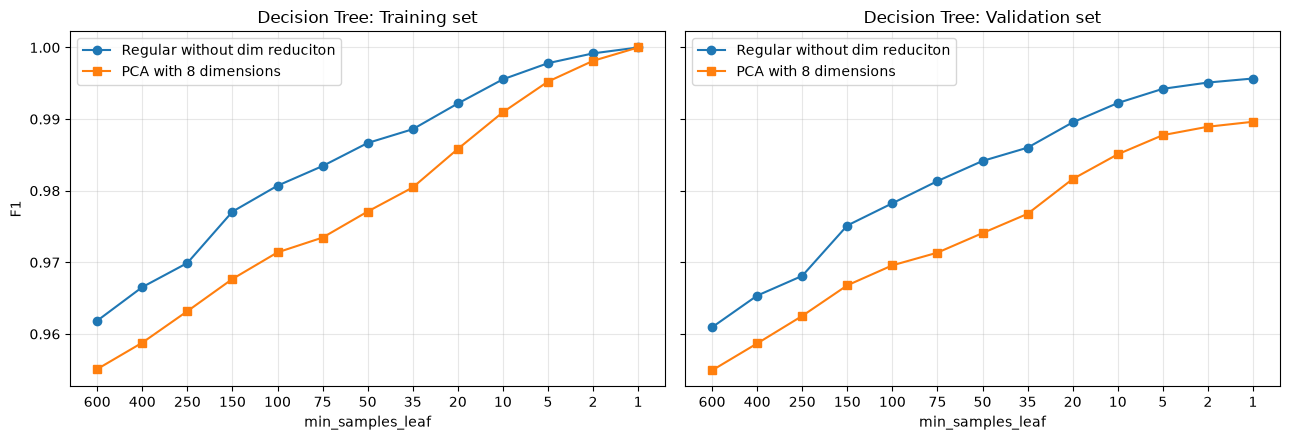

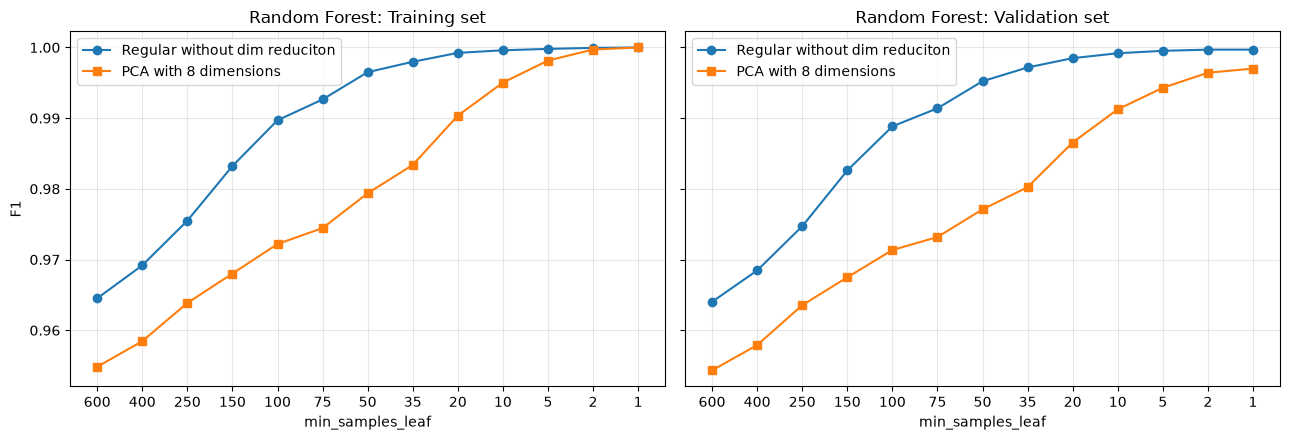

In [16]:
def plot_f1(raw, pca, title, xlabel):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for ax, key, name in zip(axes, ["train_f1", "val_f1"], ["Training set", "Validation set"]):
        ax.plot(range(len(raw["params"])), raw[key], marker="o", label="Regular without dim reduciton")
        ax.plot(range(len(pca["params"])), pca[key], marker="s", label="PCA with 8 dimensions")
        ax.set_xticks(range(len(raw["params"])))
        ax.set_xticklabels(raw["params"])
        ax.set_title(f"{title}: {name}")
        ax.set_xlabel(xlabel)
        ax.grid(alpha=0.3)
        ax.legend()
    axes[0].set_ylabel("F1")
    plt.tight_layout()
    plt.show()

plot_f1(dt_no_dim_reduct, dt_pca, "Decision Tree", "min_samples_leaf")
plot_f1(rf_no_dim_reduct, rf_pca, "Random Forest", "min_samples_leaf")
